In [1]:

import sys
import platform

print("Python version:", sys.version)
print("Operating system:", platform.system())
print("Machine:", platform.machine())

Python version: 3.13.5 | packaged by Anaconda, Inc. | (main, Jun 12 2025, 11:23:37) [Clang 14.0.6 ]
Operating system: Darwin
Machine: arm64


In [2]:
import torch
import ultralytics
import pandas as pd
import matplotlib.pyplot as plt

print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)
print("Pandas:", pd.__version__)

device = "mps" if torch.backends.mps.is_available() else "cpu"

print("\nSelected device:", device)

PyTorch: 2.15.0
Ultralytics: 8.4.208
Pandas: 2.2.3

Selected device: mps


In [3]:
%pip install ultralytics huggingface_hub datasets pandas numpy matplotlib seaborn pillow scikit-learn

  Using cached numpy-2.5.4-cp313-cp313-macosx_14_0_arm64.whl.metadata (6.6 kB)
  Using cached numpy-2.4.6-cp313-cp313-macosx_14_0_arm64.whl.metadata (6.6 kB)
Using cached numpy-2.4.6-cp313-cp313-macosx_14_0_arm64.whl (5.2 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 2.1.3
    Uninstalling numpy-2.1.3:
      Successfully uninstalled numpy-2.1.3
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
numba 0.61.0 requires numpy<2.2,>=1.24, but you have numpy 2.4.6 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


In [4]:
%pip install numpy==2.1.3

  Using cached numpy-2.1.3-cp313-cp313-macosx_14_0_arm64.whl.metadata (62 kB)
Using cached numpy-2.1.3-cp313-cp313-macosx_14_0_arm64.whl (5.1 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 2.4.6
    Uninstalling numpy-2.4.6:
      Successfully uninstalled numpy-2.4.6
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ultralytics 8.4.208 requires numpy!=2.0.*,!=2.1.*,!=2.2.*,!=2.3.0,!=2.3.1,!=2.3.2,!=2.3.3,!=2.3.4,>=1.23.0; platform_system == "Darwin", but you have numpy 2.1.3 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


In [5]:
import numpy as np
import torch
import ultralytics
import pandas as pd
import matplotlib

print("NumPy:", np.__version__)
print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", matplotlib.__version__)

print("Apple GPU:", torch.backends.mps.is_available())

NumPy: 2.1.3
PyTorch: 2.15.0
Ultralytics: 8.4.208
Pandas: 2.2.3
Matplotlib: 3.10.0
Apple GPU: True


In [6]:
import os

data_path = "data"

for root, dirs, files in os.walk(data_path):
    print(root, "->", len(files), "files")

In [8]:
base_path = os.path.expanduser("~/Downloads/VisDrone")

In [9]:
train_path = os.path.join(
    base_path,
    "VisDrone2019-DET-train"
)

images_path = os.path.join(train_path, "images")
annotations_path = os.path.join(train_path, "annotations")

print("Training folder:", os.path.exists(train_path))
print("Images folder:", os.path.exists(images_path))
print("Annotations folder:", os.path.exists(annotations_path))

print("Number of training images:", len(os.listdir(images_path)))
print("Number of annotations:", len(os.listdir(annotations_path)))

Training folder: True
Images folder: True
Annotations folder: True
Number of training images: 6471
Number of annotations: 6471


In [10]:
import os

# Search for YOLO model weights inside VisDrone
print("Searching for model weights...\n")

for root, dirs, files in os.walk(base_path):
    for file in files:
        if file.endswith(".pt"):
            print(os.path.join(root, file))

Searching for model weights...

/Users/anchanasanthosh/Downloads/VisDrone/best.pt
/Users/anchanasanthosh/Downloads/VisDrone/yolo11m.pt


In [11]:
val_path = os.path.join(
    base_path, "VisDrone2019-DET-val"
)


test_path = os.path.join(
    base_path, "VisDrone2019-DET-test-dev"
)

print("Validation images:",
      len(os.listdir(os.path.join(val_path, "images"))))

print("Test images:",
      len(os.listdir(os.path.join(test_path, "images"))))

Validation images: 548
Test images: 1610


In [12]:
import os

downloads = os.path.expanduser("~/Downloads")

print("Searching Downloads for model weights...\n")

for root, dirs, files in os.walk(downloads):
    # Avoid unnecessary large directories
    dirs[:] = [d for d in dirs if d not in [
        ".Trash", "__pycache__", ".git"
    ]]

    for file in files:
        if file.endswith((".pt", ".pth", ".onnx")):
            print(os.path.join(root, file))

Searching Downloads for model weights...

/Users/anchanasanthosh/Downloads/assignment_01_ws2627/assignment_01/yolo11m.pt
/Users/anchanasanthosh/Downloads/4/demo/tree.pt
/Users/anchanasanthosh/Downloads/4/hidden_tests/imbalanced.pt
/Users/anchanasanthosh/Downloads/4/hidden_tests/same_feature_diff_label.pt
/Users/anchanasanthosh/Downloads/4/hidden_tests/linearly_separable.pt
/Users/anchanasanthosh/Downloads/4/hidden_tests/identical_points.pt
/Users/anchanasanthosh/Downloads/4/hidden_tests/single_point.pt
/Users/anchanasanthosh/Downloads/4/hidden_tests/checkers.pt
/Users/anchanasanthosh/Downloads/4/hidden_tests/overfit.pt
/Users/anchanasanthosh/Downloads/4/hidden_tests/one_class.pt
/Users/anchanasanthosh/Downloads/VisDrone/best.pt
/Users/anchanasanthosh/Downloads/VisDrone/yolo11m.pt


In [13]:
from ultralytics import YOLO
import os

model_path = os.path.expanduser("~/Downloads/VisDrone/best.pt")

print("Model exists:", os.path.exists(model_path))

Model exists: True


In [14]:
finetuned_model = YOLO(model_path)

print("Fine-tuned model loaded successfully!")

Fine-tuned model loaded successfully!


In [15]:
original_model = YOLO("yolo11m.pt")

print("Original YOLO11m loaded successfully!")

Original YOLO11m loaded successfully!


In [16]:

# Verify that both models are loaded

print("Fine-tuned model:", type(finetuned_model).__name__)
print("Original model:", type(original_model).__name__)

print("\nFine-tuned classes:")
print(finetuned_model.names)

print("\nOriginal COCO classes:")
print(original_model.names)


Fine-tuned model: YOLO
Original model: YOLO

Fine-tuned classes:
{0: 'pedestrian', 1: 'people', 2: 'bicycle', 3: 'car', 4: 'van', 5: 'truck', 6: 'tricycle', 7: 'awning-tricycle', 8: 'bus', 9: 'motor', 10: 'others'}

Original COCO classes:
{0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 5

========== MODEL COMPARISON ==========

Fine-tuned YOLO11m
Total detections: 801
Average confidence: 0.593
Class distribution: Counter({'car': 442, 'pedestrian': 108, 'motor': 106, 'people': 63, 'van': 48, 'bicycle': 11, 'truck': 9, 'tricycle': 6, 'awning-tricycle': 4, 'bus': 4})

Original YOLO11m
Total detections: 365
Average confidence: 0.573
Class distribution: Counter({'car': 246, 'person': 72, 'truck': 16, 'motorcycle': 9, 'traffic light': 8, 'bus': 4, 'bicycle': 4, 'potted plant': 3, 'umbrella': 1, 'stop sign': 1, 'backpack': 1})


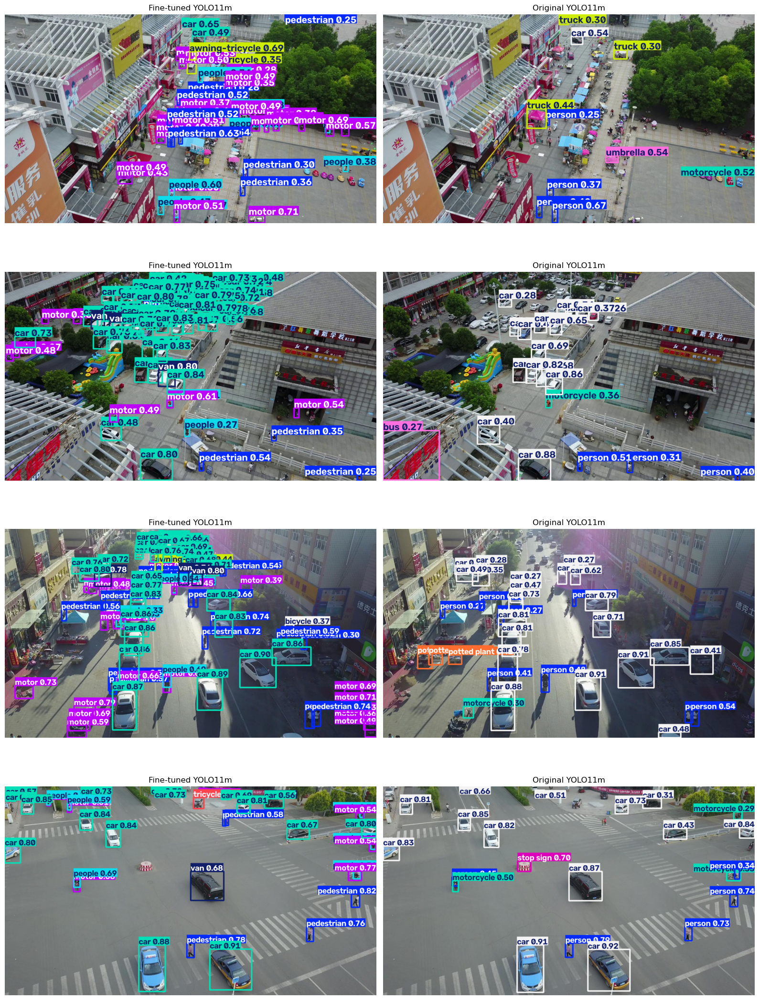

In [17]:

import os
import random
import matplotlib.pyplot as plt
from collections import Counter

# Use the validation images
images_dir = os.path.join(val_path, "images")

image_files = [
    os.path.join(images_dir, f)
    for f in os.listdir(images_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

# Select a reproducible sample of 20 images
random.seed(42)
sample_images = random.sample(image_files, min(20, len(image_files)))

# Store results
comparison_results = []
fine_counts = Counter()
original_counts = Counter()

fine_confidences = []
original_confidences = []

for img_path in sample_images:

    # Same input and settings for both models
    fine_result = finetuned_model.predict(
        source=img_path,
        conf=0.25,
        imgsz=640,
        verbose=False
    )[0]

    original_result = original_model.predict(
        source=img_path,
        conf=0.25,
        imgsz=640,
        verbose=False
    )[0]

    # Count detections
    for cls, conf in zip(
        fine_result.boxes.cls.cpu().tolist(),
        fine_result.boxes.conf.cpu().tolist()
    ):
        fine_counts[finetuned_model.names[int(cls)]] += 1
        fine_confidences.append(conf)

    for cls, conf in zip(
        original_result.boxes.cls.cpu().tolist(),
        original_result.boxes.conf.cpu().tolist()
    ):
        original_counts[original_model.names[int(cls)]] += 1
        original_confidences.append(conf)

    comparison_results.append(
        (img_path, fine_result, original_result)
    )

# Overall summary
print("========== MODEL COMPARISON ==========")

print("\nFine-tuned YOLO11m")
print("Total detections:", sum(fine_counts.values()))
print("Average confidence:",
      round(sum(fine_confidences) / max(len(fine_confidences), 1), 3))
print("Class distribution:", fine_counts)

print("\nOriginal YOLO11m")
print("Total detections:", sum(original_counts.values()))
print("Average confidence:",
      round(sum(original_confidences) / max(len(original_confidences), 1), 3))
print("Class distribution:", original_counts)

# Visualize first four images
fig, axes = plt.subplots(4, 2, figsize=(16, 22))

for i, (img_path, fine, original) in enumerate(comparison_results[:4]):

    axes[i, 0].imshow(fine.plot()[:, :, ::-1])
    axes[i, 0].set_title("Fine-tuned YOLO11m")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(original.plot()[:, :, ::-1])
    axes[i, 1].set_title("Original YOLO11m")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()



Analysing: Fine-tuned YOLO11m
Images analysed: 548
Total detections: 25992
Average detections per image: 47.43
Median detections per image: 46.0
Average confidence: 0.585
Class distribution: Counter({'car': 12510, 'pedestrian': 4495, 'motor': 3506, 'people': 2459, 'van': 1225, 'tricycle': 528, 'bicycle': 446, 'truck': 388, 'awning-tricycle': 272, 'bus': 163})

Analysing: Original YOLO11m
Images analysed: 548
Total detections: 10661
Average detections per image: 19.45
Median detections per image: 20.0
Average confidence: 0.562
Class distribution: Counter({'car': 6856, 'person': 2281, 'truck': 495, 'motorcycle': 446, 'traffic light': 201, 'bus': 121, 'bicycle': 105, 'cell phone': 62, 'umbrella': 29, 'potted plant': 25, 'bench': 8, 'stop sign': 7, 'backpack': 6, 'train': 4, 'dog': 3, 'tennis racket': 2, 'skateboard': 2, 'boat': 2, 'cow': 1, 'suitcase': 1, 'dining table': 1, 'handbag': 1, 'frisbee': 1, 'clock': 1})


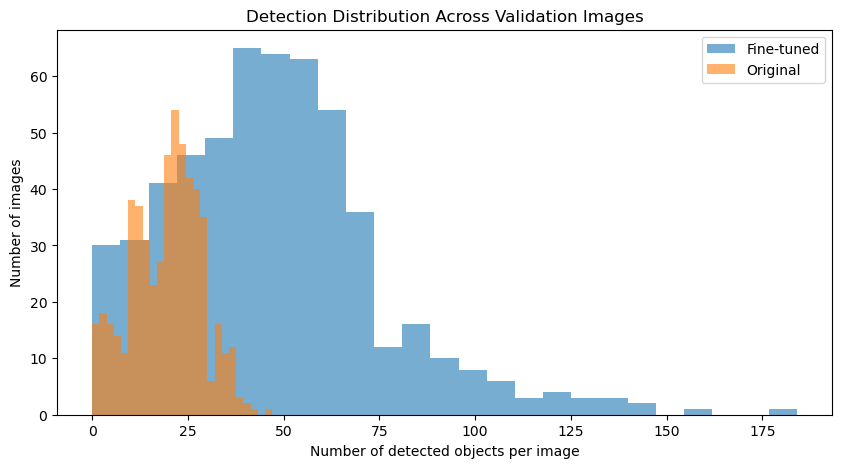

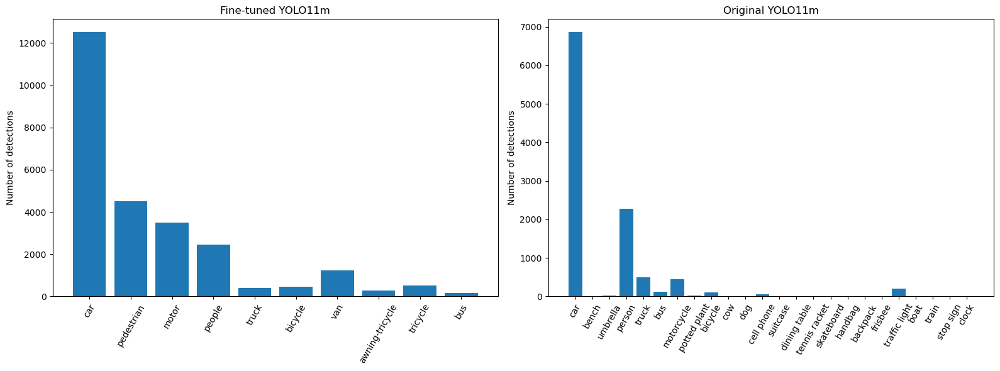

In [18]:

from collections import Counter
import numpy as np
import matplotlib.pyplot as plt

models = {
    "Fine-tuned YOLO11m": finetuned_model,
    "Original YOLO11m": original_model
}

full_results = {}

for model_name, model in models.items():

    print(f"\nAnalysing: {model_name}")

    class_counts = Counter()
    detections_per_image = []
    confidences = []

    results = model.predict(
        source=images_dir,
        conf=0.25,
        imgsz=640,
        stream=True,
        verbose=False
    )

    for result in results:

        boxes = result.boxes
        detections_per_image.append(len(boxes))

        for cls, conf in zip(
            boxes.cls.cpu().tolist(),
            boxes.conf.cpu().tolist()
        ):
            class_name = model.names[int(cls)]
            class_counts[class_name] += 1
            confidences.append(conf)

    full_results[model_name] = {
        "class_counts": class_counts,
        "per_image": detections_per_image,
        "confidences": confidences
    }

    print("Images analysed:", len(detections_per_image))
    print("Total detections:", sum(class_counts.values()))
    print("Average detections per image:",
          round(np.mean(detections_per_image), 2))
    print("Median detections per image:",
          round(np.median(detections_per_image), 2))
    print("Average confidence:",
          round(np.mean(confidences), 3))
    print("Class distribution:", class_counts)

# Compare detections per image
plt.figure(figsize=(10, 5))

plt.hist(
    full_results["Fine-tuned YOLO11m"]["per_image"],
    bins=25,
    alpha=0.6,
    label="Fine-tuned"
)

plt.hist(
    full_results["Original YOLO11m"]["per_image"],
    bins=25,
    alpha=0.6,
    label="Original"
)

plt.xlabel("Number of detected objects per image")
plt.ylabel("Number of images")
plt.title("Detection Distribution Across Validation Images")
plt.legend()
plt.show()

# Compare class distributions separately
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, model_name in zip(axes, models.keys()):

    counts = full_results[model_name]["class_counts"]

    ax.bar(counts.keys(), counts.values())
    ax.set_title(model_name)
    ax.set_ylabel("Number of detections")
    ax.tick_params(axis="x", rotation=60)

plt.tight_layout()
plt.show()


CONFIDENCE COMPARISON
---------------------------------------------

Fine-tuned YOLO11m
Mean: 0.585
Median: 0.602
Standard deviation: 0.196
Below 0.50: 37.11 %
Above 0.75: 27.34 %

Original YOLO11m
Mean: 0.562
Median: 0.55
Standard deviation: 0.201
Below 0.50: 43.12 %
Above 0.75: 24.4 %


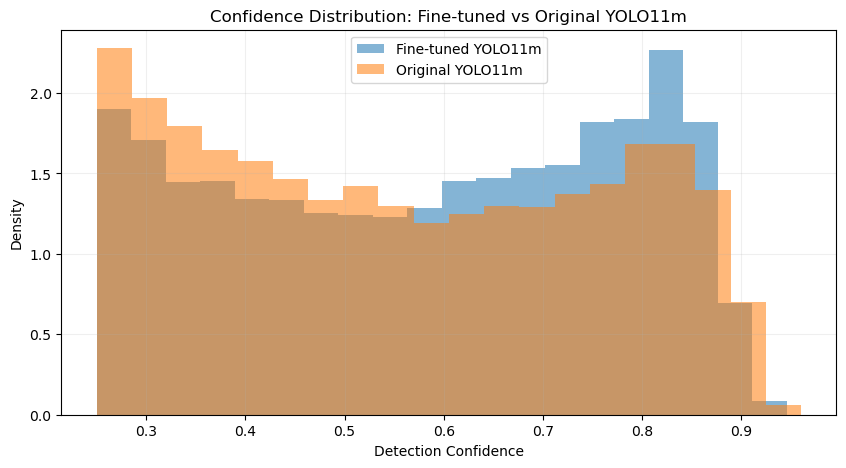

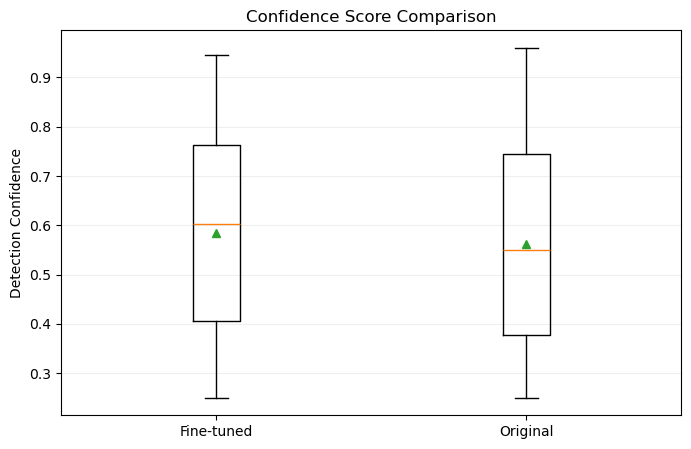

In [19]:

# STEP 1: Confidence Distribution Comparison

fine_conf = full_results["Fine-tuned YOLO11m"]["confidences"]
orig_conf = full_results["Original YOLO11m"]["confidences"]

# Print statistical comparison
print("CONFIDENCE COMPARISON")
print("-" * 45)

for name, values in [
    ("Fine-tuned YOLO11m", fine_conf),
    ("Original YOLO11m", orig_conf)
]:
    print(f"\n{name}")
    print("Mean:", round(np.mean(values), 3))
    print("Median:", round(np.median(values), 3))
    print("Standard deviation:", round(np.std(values), 3))
    print("Below 0.50:", round(np.mean(np.array(values) < 0.50) * 100, 2), "%")
    print("Above 0.75:", round(np.mean(np.array(values) > 0.75) * 100, 2), "%")

# Plot normalized confidence distributions
plt.figure(figsize=(10, 5))

plt.hist(
    fine_conf,
    bins=20,
    density=True,
    alpha=0.55,
    label="Fine-tuned YOLO11m"
)

plt.hist(
    orig_conf,
    bins=20,
    density=True,
    alpha=0.55,
    label="Original YOLO11m"
)

plt.xlabel("Detection Confidence")
plt.ylabel("Density")
plt.title("Confidence Distribution: Fine-tuned vs Original YOLO11m")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

# Boxplot comparison
plt.figure(figsize=(8, 5))

plt.boxplot(
    [fine_conf, orig_conf],
    tick_labels=["Fine-tuned", "Original"],
    showmeans=True
)

plt.ylabel("Detection Confidence")
plt.title("Confidence Score Comparison")
plt.grid(axis="y", alpha=0.2)
plt.show()


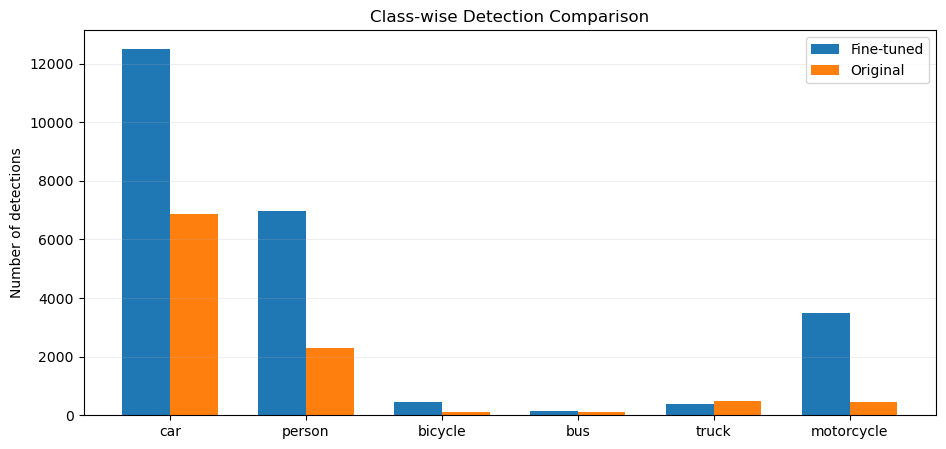

CLASS COMPARISON
car          Fine-tuned:  12510 | Original:   6856
person       Fine-tuned:   6954 | Original:   2281
bicycle      Fine-tuned:    446 | Original:    105
bus          Fine-tuned:    163 | Original:    121
truck        Fine-tuned:    388 | Original:    495
motorcycle   Fine-tuned:   3506 | Original:    446


In [20]:

# STEP 2: Compare common object categories

fine_counts = full_results["Fine-tuned YOLO11m"]["class_counts"]
orig_counts = full_results["Original YOLO11m"]["class_counts"]

# Approximate semantic mapping for comparable categories
class_mapping = {
    "car": "car",
    "pedestrian": "person",
    "people": "person",
    "bicycle": "bicycle",
    "bus": "bus",
    "truck": "truck",
    "motor": "motorcycle"
}

mapped_original = Counter()

for class_name, count in orig_counts.items():
    mapped_original[class_name] += count

mapped_finetuned = Counter()

for class_name, count in fine_counts.items():
    mapped_finetuned[class_mapping.get(class_name, class_name)] += count

# Plot selected comparable classes
common_classes = [
    "car", "person", "bicycle",
    "bus", "truck", "motorcycle"
]

fine_values = [mapped_finetuned[c] for c in common_classes]
orig_values = [mapped_original[c] for c in common_classes]

x = np.arange(len(common_classes))
width = 0.35

plt.figure(figsize=(11, 5))

plt.bar(x - width/2, fine_values, width, label="Fine-tuned")
plt.bar(x + width/2, orig_values, width, label="Original")

plt.xticks(x, common_classes)
plt.ylabel("Number of detections")
plt.title("Class-wise Detection Comparison")
plt.legend()
plt.grid(axis="y", alpha=0.2)
plt.show()

print("CLASS COMPARISON")
for c, f, o in zip(common_classes, fine_values, orig_values):
    print(f"{c:12s} Fine-tuned: {f:6d} | Original: {o:6d}")


In [21]:
from pathlib import Path

BASE_DIR = Path.home() / "Downloads" / "VisDrone"

print("Checking VisDrone dataset structure:\n")

for folder in BASE_DIR.iterdir():
    if folder.is_dir():
        print(f"\n{folder.name}")

        for subfolder in folder.iterdir():
            if subfolder.is_dir():
                print("   ", subfolder.name)

Checking VisDrone dataset structure:


VisDrone2019-DET-test-dev
    images
    annotations

VisDrone2019-DET-val
    images
    annotations

VisDrone2019-DET-test-dev 2
    images
    annotations

VisDrone2019-DET-val 2
    images
    annotations

VisDrone2019-DET-train 2
    images
    annotations

.ipynb_checkpoints

VisDrone2019-DET-train
    images
    annotations


In [22]:
from pathlib import Path

BASE_DIR = Path.home() / "Downloads" / "VisDrone"

VAL_IMAGES = BASE_DIR / "VisDrone2019-DET-val 2" / "images"
VAL_ANNOTATIONS = BASE_DIR / "VisDrone2019-DET-val 2" / "annotations"

image_files = {
    p.stem for p in VAL_IMAGES.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
}

annotation_files = {
    p.stem for p in VAL_ANNOTATIONS.glob("*.txt")
}

print("Validation images:", len(image_files))
print("Annotation files:", len(annotation_files))
print("Images with annotations:", len(image_files & annotation_files))
print("Images without annotations:", len(image_files - annotation_files))
print("Annotations without images:", len(annotation_files - image_files))

print("\nExample annotation file:")
example = next(iter(VAL_ANNOTATIONS.glob("*.txt")), None)

if example:
    print("File:", example.name)
    print(example.read_text().splitlines()[:5])

Validation images: 548
Annotation files: 548
Images with annotations: 548
Images without annotations: 0
Annotations without images: 0

Example annotation file:
File: 0000327_03601_d_0000729.txt
['503,73,24,11,1,4,0,0', '504,87,31,16,1,5,0,1', '524,94,23,12,1,4,0,1', '492,100,29,15,1,4,0,1', '459,131,31,19,1,5,0,1']


In [23]:
from collections import Counter

# Inspect annotation format
category_counts = Counter()
total_objects = 0

for file in VAL_ANNOTATIONS.glob("*.txt"):
    for line in file.read_text().splitlines():
        values = line.strip().split(",")

        if len(values) == 8:
            category = int(values[5])
            category_counts[category] += 1
            total_objects += 1

print("Total annotated objects:", total_objects)

print("\nGround-truth category distribution:")
for category, count in sorted(category_counts.items()):
    print(f"Category {category}: {count}")

# Inspect existing model variables
print("\nMODEL VARIABLES")

for name in ["finetuned_model", "original_model"]:
    if name in globals():
        model = globals()[name]
        print(f"\n{name}:")
        print("Model type:", type(model))
        print("Class names:", model.names)
    else:
        print(f"{name}: NOT FOUND")

Total annotated objects: 40169

Ground-truth category distribution:
Category 0: 1378
Category 1: 8844
Category 2: 5125
Category 3: 1287
Category 4: 14064
Category 5: 1975
Category 6: 750
Category 7: 1045
Category 8: 532
Category 9: 251
Category 10: 4886
Category 11: 32

MODEL VARIABLES

finetuned_model:
Model type: <class 'ultralytics.models.yolo.model.YOLO'>
Class names: {0: 'pedestrian', 1: 'people', 2: 'bicycle', 3: 'car', 4: 'van', 5: 'truck', 6: 'tricycle', 7: 'awning-tricycle', 8: 'bus', 9: 'motor', 10: 'others'}

original_model:
Model type: <class 'ultralytics.models.yolo.model.YOLO'>
Class names: {0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie

In [24]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Use the validation directories already defined in the notebook
VAL_IMAGES = Path(VAL_IMAGES)
VAL_ANNOTATIONS = Path(VAL_ANNOTATIONS)

SMALL_AREA_THRESHOLD = 32 * 32
CROWD_THRESHOLD = 30

scene_results = []

# Analyse every validation annotation file
for annotation_file in VAL_ANNOTATIONS.glob("*.txt"):

    image_file = VAL_IMAGES / f"{annotation_file.stem}.jpg"

    if not image_file.exists():
        continue

    total_objects = 0
    small_objects = 0

    with open(annotation_file, "r") as f:
        for line in f:
            values = line.strip().split(",")

            if len(values) < 6:
                continue

            x, y, w, h = map(float, values[:4])
            category_id = int(values[5])

            # Exclude ignored regions (category 0)
            if category_id == 0 or w <= 0 or h <= 0:
                continue

            total_objects += 1

            if w * h <= SMALL_AREA_THRESHOLD:
                small_objects += 1

    scene_results.append({
        "image": image_file,
        "image_name": image_file.name,
        "total_objects": total_objects,
        "small_objects": small_objects,
        "small_object_percentage": (
            100 * small_objects / total_objects
            if total_objects > 0 else 0
        ),
        "crowded": total_objects >= CROWD_THRESHOLD
    })

# Create a results table
scene_df = pd.DataFrame(scene_results)

print("Total validation images analysed:", len(scene_df))
print("\nTOP 10 IMAGES WITH MOST SMALL OBJECTS")

display(
    scene_df.sort_values(
        "small_objects", ascending=False
    ).head(10)[[
        "image_name",
        "total_objects",
        "small_objects",
        "small_object_percentage"
    ]]
)

print("\nTOP 10 MOST CROWDED IMAGES")

display(
    scene_df.sort_values(
        "total_objects", ascending=False
    ).head(10)[[
        "image_name",
        "total_objects",
        "small_objects",
        "crowded"
    ]]
)

print("\nNumber of crowded scenes:",
      scene_df["crowded"].sum())


Total validation images analysed: 548

TOP 10 IMAGES WITH MOST SMALL OBJECTS


,image_name,total_objects,small_objects,small_object_percentage
103,0000295_02400_d_0000033.jpg,317,280,88.328076
129,0000295_01800_d_0000030.jpg,306,269,87.908497
397,0000295_02000_d_0000031.jpg,311,261,83.922830
252,0000295_01000_d_0000026.jpg,251,226,90.039841
408,0000295_01200_d_0000027.jpg,200,182,91.000000
436,0000295_02900_d_0000034.jpg,212,172,81.132075
16,0000295_01400_d_0000028.jpg,189,172,91.005291
234,0000291_03201_d_0000884.jpg,229,170,74.235808
227,0000295_00600_d_0000024.jpg,186,166,89.247312
498,0000086_01954_d_0000005.jpg,173,163,94.219653



TOP 10 MOST CROWDED IMAGES


,image_name,total_objects,small_objects,crowded
103,0000295_02400_d_0000033.jpg,317,280,True
397,0000295_02000_d_0000031.jpg,311,261,True
129,0000295_01800_d_0000030.jpg,306,269,True
252,0000295_01000_d_0000026.jpg,251,226,True
234,0000291_03201_d_0000884.jpg,229,170,True
436,0000295_02900_d_0000034.jpg,212,172,True
21,0000291_01201_d_0000874.jpg,212,135,True
420,0000291_05201_d_0000893.jpg,207,143,True
408,0000295_01200_d_0000027.jpg,200,182,True
189,0000295_02200_d_0000032.jpg,193,134,True



Number of crowded scenes: 452


Selected images for model analysis: 6


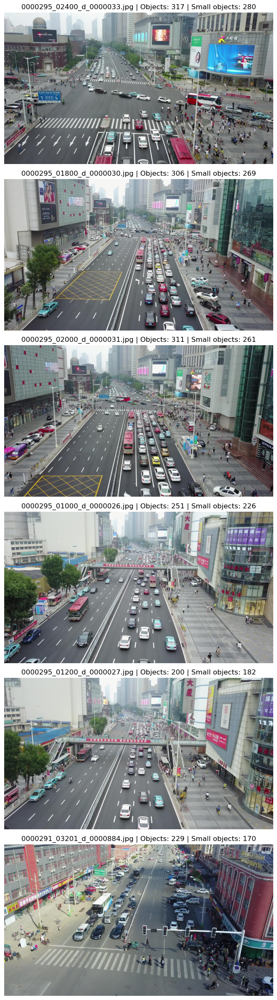

In [25]:


# Select representative images:
# 5 with the most small objects and 5 with the most objects overall

small_scene_images = scene_df.nlargest(
    5, "small_objects"
)

crowded_scene_images = scene_df.nlargest(
    5, "total_objects"
)

selected_scenes = pd.concat([
    small_scene_images,
    crowded_scene_images
]).drop_duplicates(subset="image_name")

print("Selected images for model analysis:",
      len(selected_scenes))

fig, axes = plt.subplots(
    len(selected_scenes), 1,
    figsize=(12, 4 * len(selected_scenes))
)

if len(selected_scenes) == 1:
    axes = [axes]

for ax, (_, row) in zip(
    axes, selected_scenes.iterrows()
):
    image = Image.open(row["image"])

    ax.imshow(image)
    ax.set_title(
        f'{row["image_name"]} | '
        f'Objects: {row["total_objects"]} | '
        f'Small objects: {row["small_objects"]}'
    )
    ax.axis("off")

plt.tight_layout()
plt.show()


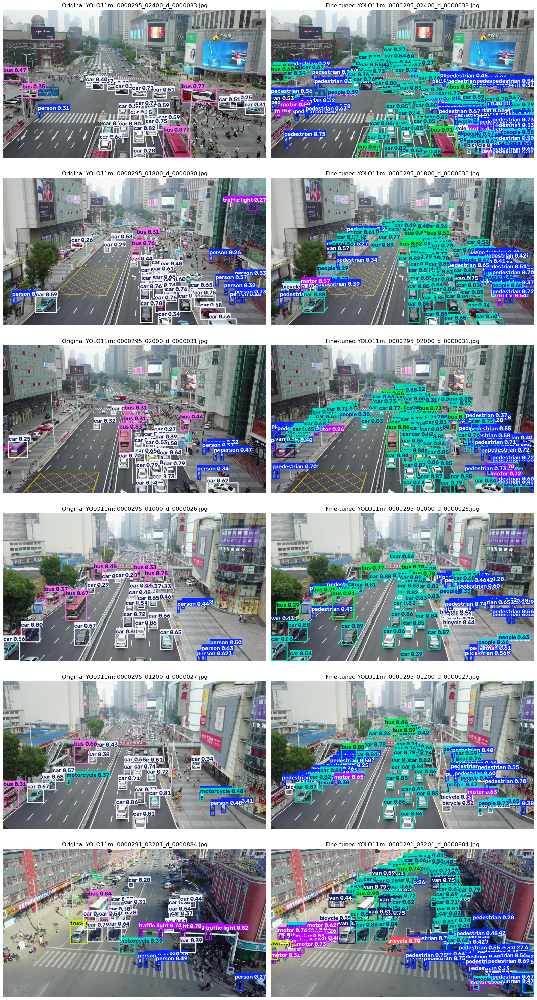

In [26]:

# STEP 7: Side-by-side comparison of both models

fig, axes = plt.subplots(
    len(selected_scenes), 2,
    figsize=(16, 5 * len(selected_scenes))
)

for i, (_, row) in enumerate(selected_scenes.iterrows()):

    image_path = str(row["image"])

    # Original COCO model
    original_result = original_model.predict(
        source=image_path,
        conf=0.25,
        imgsz=640,
        verbose=False
    )[0]

    # Fine-tuned VisDrone model
    finetuned_result = finetuned_model.predict(
        source=image_path,
        conf=0.25,
        imgsz=640,
        verbose=False
    )[0]

    # Convert BGR to RGB for matplotlib
    original_plot = original_result.plot()[:, :, ::-1]
    finetuned_plot = finetuned_result.plot()[:, :, ::-1]

    axes[i, 0].imshow(original_plot)
    axes[i, 0].set_title(
        f'Original YOLO11m: {row["image_name"]}'
    )
    axes[i, 0].axis("off")

    axes[i, 1].imshow(finetuned_plot)
    axes[i, 1].set_title(
        f'Fine-tuned YOLO11m: {row["image_name"]}'
    )
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()


In [27]:

# STEP 8: Quantitative comparison per image

comparison_data = []

for _, row in selected_scenes.iterrows():

    image_path = str(row["image"])

    original_result = original_model.predict(
        source=image_path,
        conf=0.25,
        imgsz=640,
        verbose=False
    )[0]

    finetuned_result = finetuned_model.predict(
        source=image_path,
        conf=0.25,
        imgsz=640,
        verbose=False
    )[0]

    original_count = len(original_result.boxes)
    finetuned_count = len(finetuned_result.boxes)

    original_conf = (
        original_result.boxes.conf.mean().item()
        if original_count > 0 else 0
    )

    finetuned_conf = (
        finetuned_result.boxes.conf.mean().item()
        if finetuned_count > 0 else 0
    )

    comparison_data.append({
        "Image": row["image_name"],
        "Original detections": original_count,
        "Fine-tuned detections": finetuned_count,
        "Original avg confidence": round(original_conf, 3),
        "Fine-tuned avg confidence": round(finetuned_conf, 3)
    })

comparison_df = pd.DataFrame(comparison_data)

display(comparison_df)

print("\nTOTAL DETECTIONS")
print("Original:",
      comparison_df["Original detections"].sum())

print("Fine-tuned:",
      comparison_df["Fine-tuned detections"].sum())


,Image,Original detections,Fine-tuned detections,Original avg confidence,Fine-tuned avg confidence
0,0000295_02400_d_0000033.jpg,25,184,0.542,0.478
1,0000295_01800_d_0000030.jpg,34,126,0.524,0.537
2,0000295_02000_d_0000031.jpg,28,126,0.489,0.571
3,0000295_01000_d_0000026.jpg,29,78,0.528,0.592
4,0000295_01200_d_0000027.jpg,23,74,0.573,0.563
5,0000291_03201_d_0000884.jpg,28,142,0.449,0.516



TOTAL DETECTIONS
Original: 167
Fine-tuned: 730


In [28]:

# STEP 8: Ground-truth-based evaluation of both models

import numpy as np
import pandas as pd
from collections import defaultdict

# Common categories for a fair comparison
COMMON_CLASSES = [
    "person", "bicycle", "car",
    "truck", "bus", "motorcycle"
]

# VisDrone ground-truth category mapping
gt_class_map = {
    1: "person",
    2: "person",
    3: "bicycle",
    4: "car",
    6: "truck",
    9: "bus",
    10: "motorcycle"
}

# Model class-name mapping
def map_model_class(name, model_type):

    name = str(name).lower()

    if model_type == "finetuned":
        mapping = {
            "pedestrian": "person",
            "people": "person",
            "bicycle": "bicycle",
            "car": "car",
            "truck": "truck",
            "bus": "bus",
            "motor": "motorcycle"
        }
    else:
        mapping = {
            "person": "person",
            "bicycle": "bicycle",
            "car": "car",
            "truck": "truck",
            "bus": "bus",
            "motorcycle": "motorcycle"
        }

    return mapping.get(name)


# Calculate Intersection over Union
def calculate_iou(box1, box2):

    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2-x1) * max(0, y2-y1)

    area1 = max(0, box1[2]-box1[0]) * max(0, box1[3]-box1[1])
    area2 = max(0, box2[2]-box2[0]) * max(0, box2[3]-box2[1])

    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0


# Evaluate one model
def evaluate_model(model, model_type):

    counts = defaultdict(lambda: {
        "TP": 0, "FP": 0, "FN": 0
    })

    image_paths = sorted([
        p for p in VAL_IMAGES.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ])

    for image_path in image_paths:

        annotation_path = VAL_ANNOTATIONS / (image_path.stem + ".txt")

        if not annotation_path.exists():
            continue

        # Read valid ground-truth annotations
        gt_objects = defaultdict(list)

        for line in annotation_path.read_text().splitlines():

            values = line.replace(",", " ").split()

            if len(values) < 8:
                continue

            x, y, w, h = map(float, values[:4])
            score = int(float(values[4]))
            category = int(float(values[5]))

            if score != 1 or category not in gt_class_map:
                continue

            label = gt_class_map[category]

            if label not in COMMON_CLASSES:
                continue

            gt_box = [x, y, x+w, y+h]
            gt_objects[label].append(gt_box)

        # Run model prediction
        result = model.predict(
            source=str(image_path),
            conf=0.25,
            imgsz=640,
            verbose=False
        )[0]

        predictions = defaultdict(list)

        if result.boxes is not None:

            for box, confidence, class_id in zip(
                result.boxes.xyxy.cpu().numpy(),
                result.boxes.conf.cpu().numpy(),
                result.boxes.cls.cpu().numpy()
            ):

                class_name = model.names[int(class_id)]
                label = map_model_class(class_name, model_type)

                if label in COMMON_CLASSES:
                    predictions[label].append(
                        (box.tolist(), float(confidence))
                    )

        # Match predictions with ground truth
        for label in COMMON_CLASSES:

            gt_boxes = gt_objects[label]
            pred_boxes = sorted(
                predictions[label],
                key=lambda x: x[1],
                reverse=True
            )

            matched_gt = set()

            for pred_box, confidence in pred_boxes:

                best_iou = 0
                best_index = -1

                for i, gt_box in enumerate(gt_boxes):

                    if i in matched_gt:
                        continue

                    iou = calculate_iou(pred_box, gt_box)

                    if iou > best_iou:
                        best_iou = iou
                        best_index = i

                if best_iou >= 0.5:

                    counts[label]["TP"] += 1
                    matched_gt.add(best_index)

                else:
                    counts[label]["FP"] += 1

            counts[label]["FN"] += (
                len(gt_boxes) - len(matched_gt)
            )

    # Prepare results
    rows = []

    total_tp = total_fp = total_fn = 0

    for label in COMMON_CLASSES:

        tp = counts[label]["TP"]
        fp = counts[label]["FP"]
        fn = counts[label]["FN"]

        precision = tp / (tp + fp) if tp + fp else 0
        recall = tp / (tp + fn) if tp + fn else 0

        f1 = (
            2 * precision * recall / (precision + recall)
            if precision + recall else 0
        )

        rows.append({
            "Class": label,
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "Precision": round(precision, 4),
            "Recall": round(recall, 4),
            "F1": round(f1, 4)
        })

        total_tp += tp
        total_fp += fp
        total_fn += fn

    precision = total_tp / (total_tp + total_fp)
    recall = total_tp / (total_tp + total_fn)

    overall_f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    return pd.DataFrame(rows), {
        "TP": total_tp,
        "FP": total_fp,
        "FN": total_fn,
        "Precision": round(precision, 4),
        "Recall": round(recall, 4),
        "F1": round(overall_f1, 4)
    }


# Evaluate both models
print("Evaluating original YOLO11m...")
original_results, original_summary = evaluate_model(
    original_model, "original"
)

print("\nEvaluating fine-tuned YOLO11m...")
finetuned_results, finetuned_summary = evaluate_model(
    finetuned_model, "finetuned"
)

print("\nORIGINAL MODEL — PER-CLASS RESULTS")
display(original_results)

print("\nFINE-TUNED MODEL — PER-CLASS RESULTS")
display(finetuned_results)

print("\nOVERALL COMPARISON")

comparison = pd.DataFrame(
    [original_summary, finetuned_summary],
    index=["Original YOLO11m", "Fine-tuned YOLO11m"]
)

display(comparison)


Evaluating original YOLO11m...

Evaluating fine-tuned YOLO11m...

ORIGINAL MODEL — PER-CLASS RESULTS


,Class,TP,FP,FN,Precision,Recall,F1
0,person,1990,291,11979,0.8724,0.1425,0.2449
1,bicycle,33,72,1254,0.3143,0.0256,0.0474
2,car,5672,1184,8392,0.8273,0.4033,0.5423
3,truck,160,335,590,0.3232,0.2133,0.2570
4,bus,73,48,178,0.6033,0.2908,0.3925
5,motorcycle,292,154,4594,0.6547,0.0598,0.1095



FINE-TUNED MODEL — PER-CLASS RESULTS


,Class,TP,FP,FN,Precision,Recall,F1
0,person,5536,1418,8433,0.7961,0.3963,0.5292
1,bicycle,213,233,1074,0.4776,0.1655,0.2458
2,car,10492,2018,3572,0.8387,0.7460,0.7896
3,truck,250,138,500,0.6443,0.3333,0.4394
4,bus,129,34,122,0.7914,0.5139,0.6232
5,motorcycle,2207,1299,2679,0.6295,0.4517,0.5260



OVERALL COMPARISON


,TP,FP,FN,Precision,Recall,F1
Original YOLO11m,8220,2084,26987,0.7977,0.2335,0.3612
Fine-tuned YOLO11m,18827,5140,16380,0.7855,0.5348,0.6363


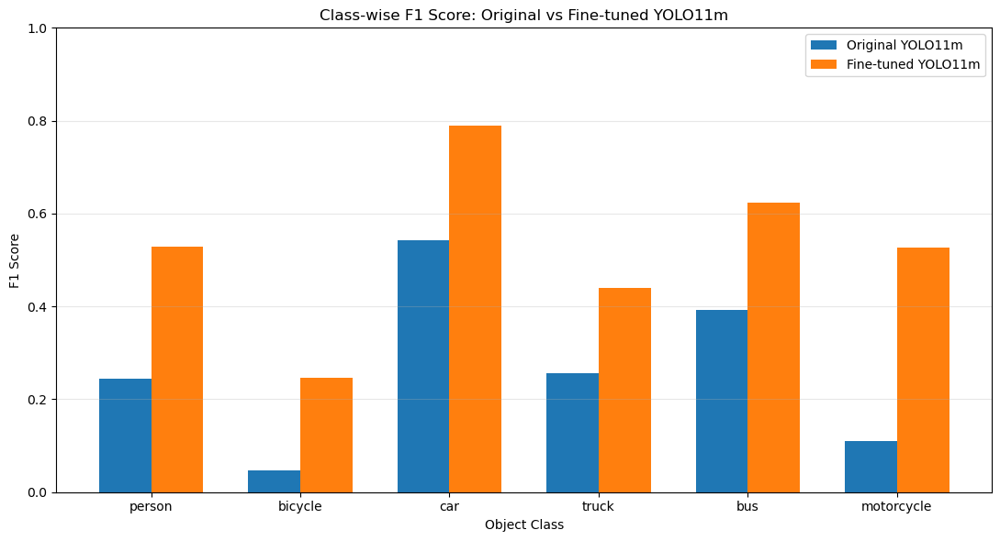

In [29]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

classes = ['person', 'bicycle', 'car', 'truck', 'bus', 'motorcycle']

original_f1 = [0.2449, 0.0474, 0.5423, 0.2570, 0.3925, 0.1095]
finetuned_f1 = [0.5292, 0.2458, 0.7896, 0.4394, 0.6232, 0.5260]

x = np.arange(len(classes))
width = 0.35

plt.figure(figsize=(11, 6))

plt.bar(x - width/2, original_f1, width, label='Original YOLO11m')
plt.bar(x + width/2, finetuned_f1, width, label='Fine-tuned YOLO11m')

plt.xticks(x, classes)
plt.ylabel('F1 Score')
plt.xlabel('Object Class')
plt.title('Class-wise F1 Score: Original vs Fine-tuned YOLO11m')
plt.ylim(0, 1)
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()

plt.savefig('phase1_class_f1_comparison.png', dpi=300)
plt.show()



##  AI Usage Documentation – Phase I

### 1. Purpose of AI assistance
Generative AI (ChatGPT) was used as an active assistant during the analysis of the original and fine-tuned YOLO11m models on the VisDrone dataset.

### 2. Important prompts used
- How can we systematically compare the predictions of the original and fine-tuned YOLO11m models?
- How can we investigate small-object detection and crowded traffic scenes?
- How can we evaluate false positives, false negatives and true positives using ground-truth annotations?
- How can we visualize class-wise differences in model performance?
- How should we interpret precision, recall and F1-score differences?

### 3. AI suggestions accepted
- Comparing both models on identical validation images.
- Analysing detection counts and confidence scores.
- Investigating small objects and crowded scenes.
- Evaluating predictions using ground-truth annotations.
- Creating a class-wise F1-score comparison chart.

### 4. Verification and corrections
AI-generated code and analytical suggestions were reviewed against the actual dataset, notebook outputs and evaluation results.

The six-image visual comparison and quantitative evaluation were used to verify the observations. Suggestions that would repeat completed work were excluded.

### 5. Observed limitations of AI assistance
- Higher detection counts do not necessarily indicate better detection performance.
- Visual examples alone cannot establish whether additional detections are correct.
- Ground-truth evaluation is necessary to distinguish correct detections from false positives and missed objects.

### 6. Conclusion
AI assistance helped structure the investigation, implement visualizations and interpret model behaviour. Final observations were based on the actual experimental outputs rather than AI suggestions alone.


# Phase I – Findings and Interpretation

## 1. Main Findings

The comparison between the original YOLO11m and fine-tuned YOLO11m models on the VisDrone validation dataset revealed several differences:

- The fine-tuned model achieved a higher overall F1 score (0.6363) compared to the original model (0.3612).
- Recall improved from 0.2335 to 0.5348, indicating that the fine-tuned model detected a substantially larger proportion of the ground-truth objects.
- Precision changed slightly from 0.7977 to 0.7855, showing a small trade-off between detecting more objects and producing false positives.
- All six evaluated classes showed improvements in their F1 scores after fine-tuning.
- The strongest improvement was observed for cars, with F1 increasing from 0.5423 to 0.7896.

## 2. Observed Model Behaviour

Visual comparisons showed that the original model produced relatively few detections in crowded traffic scenes. The fine-tuned model identified substantially more objects, including pedestrians, vehicles and smaller traffic participants.

However, the increased number of detections also resulted in overlapping bounding boxes and some potentially incorrect predictions. This suggests that higher detection counts do not automatically mean that every additional detection is correct.

## 3. Limitations

- The visual comparison was based on six selected validation images and cannot represent every possible scene.
- The quantitative evaluation covered 548 validation images.
- The analysis focused on six object classes in the current evaluation.
- Detection performance in very crowded scenes and for small objects requires further investigation.
- Aggregate metrics do not explain why particular objects are missed or incorrectly classified.

## 4. Questions for Further Investigation in Phase II

1. Why does the fine-tuned model detect substantially more objects in crowded scenes?
2. Which object classes and scene conditions still produce false positives and false negatives?
3. How does object size influence detection behaviour?
4. Why do some small or partially occluded objects remain difficult to detect?
5. What differences can be observed in the learned representations of the original and fine-tuned models?